# Faturamento de 2025: onde está o dinheiro?
**Para:** diretoria comercial · **Objetivo:** decidir onde concentrar o esforço comercial em 2026.

Esta análise olha o faturamento de 2025 por **região**, por **mês** e por **canal de venda**.
Faturamento = quantidade × preço unitário, somado venda a venda.

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.ticker import FuncFormatter

pd.set_option('display.float_format', lambda v: f'{v:,.1f}')
plt.rcParams.update({'figure.dpi': 110, 'axes.spines.top': False, 'axes.spines.right': False,
                     'axes.titleweight': 'bold', 'axes.titlelocation': 'left'})
COR, CINZA = '#1f5fa8', '#b8bec6'
mi = FuncFormatter(lambda v, _: f'R$ {v/1e6:.1f} mi'.replace('.', ','))

def fmt_mi(v): return f'R$ {v/1e6:.2f} mi'.replace('.', ',')

df = pd.read_csv('dados/vendas.csv', parse_dates=['data'])
df['faturamento'] = df['quantidade'] * df['preco_unitario']
df['lucro'] = df['quantidade'] * (df['preco_unitario'] - df['custo_unitario'])
df['mes'] = df['data'].dt.month
TOTAL = df['faturamento'].sum()
print(f'{len(df):,} vendas de {df.data.min():%d/%m/%Y} a {df.data.max():%d/%m/%Y}')
print(f'Faturamento total 2025: {fmt_mi(TOTAL)}')

5,000 vendas de 01/01/2025 a 31/12/2025
Faturamento total 2025: R$ 25,02 mi


## 1. Qualidade dos dados
Antes de somar, conferimos se há algo que distorça os números.

In [2]:
print('Valores ausentes por coluna:'); print(df.isna().sum()[lambda s: s > 0])
print('\nLinhas duplicadas:', df.duplicated().sum())
print('Vendas com custo acima do preço:', (df.custo_unitario > df.preco_unitario).sum())
print('Quantidade mín/máx:', df.quantidade.min(), df.quantidade.max())
sem_reg = df[df.regiao.isna()]
print(f'\nVendas sem região: {len(sem_reg)} ({len(sem_reg)/len(df):.1%} das vendas, {sem_reg.faturamento.sum()/TOTAL:.1%} do faturamento)')

Valores ausentes por coluna:
regiao    154
dtype: int64

Linhas duplicadas: 0
Vendas com custo acima do preço: 0
Quantidade mín/máx: 1 10

Vendas sem região: 154 (3.1% das vendas, 2.9% do faturamento)


**Único problema encontrado:** 154 vendas (3% das linhas, 2,9% do faturamento) estão **sem região**.
Não vamos descartá-las nem chutar a região: elas entram nos totais, no mês e no canal, e aparecem como **"Não informada"** nas visões por região.
O peso é pequeno e não altera a ordem das regiões. Vale pedir à área de dados que o cadastro da região seja obrigatório.

In [3]:
df['regiao'] = df['regiao'].fillna('Não informada')

## 2. Por região

,Faturamento (R$ mi),% do total,Nº de vendas,Ticket médio (R$)
regiao,,,,
Centro-Oeste,3.09,12.3%,590,"5,231"
Nordeste,4.14,16.6%,857,"4,832"
Norte,2.85,11.4%,591,"4,830"
Não informada,0.73,2.9%,154,"4,712"
Sudeste,9.83,39.3%,"1,933","5,084"
Sul,4.38,17.5%,875,"5,007"


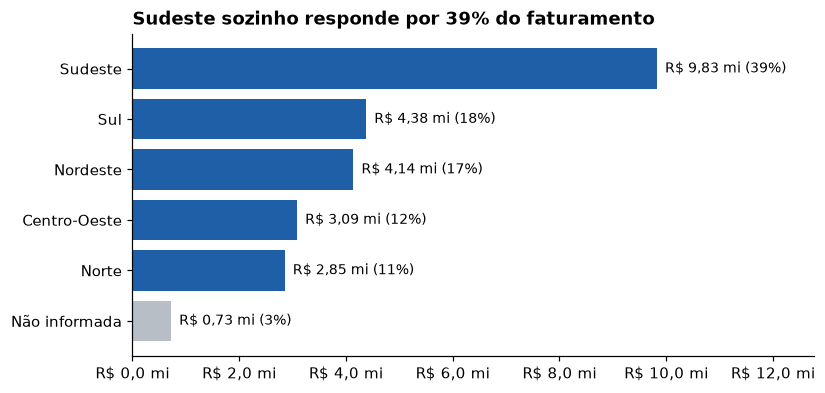

In [4]:
reg = df.groupby('regiao')['faturamento'].sum().sort_values(ascending=False)
tab = pd.DataFrame({'Faturamento (R$ mi)': reg/1e6, '% do total': reg/TOTAL*100,
                    'Nº de vendas': df.groupby('regiao').size(), 'Ticket médio (R$)': df.groupby('regiao')['faturamento'].mean()})
display(tab.style.format({'Faturamento (R$ mi)': '{:.2f}', '% do total': '{:.1f}%', 'Nº de vendas': '{:,.0f}', 'Ticket médio (R$)': '{:,.0f}'}))

ordem = reg.drop('Não informada').index.tolist() + ['Não informada']
v = reg[ordem]
fig, ax = plt.subplots(figsize=(8, 3.8))
b = ax.barh(v.index[::-1], v.values[::-1], color=[CINZA if r == 'Não informada' else COR for r in v.index[::-1]])
for r, val in zip(b, v.values[::-1]):
    ax.text(val, r.get_y()+r.get_height()/2, f'  {fmt_mi(val)} ({val/TOTAL:.0%})', va='center', fontsize=9)
ax.xaxis.set_major_formatter(mi); ax.set_xlim(0, v.max()*1.3)
ax.set_title('Sudeste sozinho responde por 39% do faturamento')
plt.show()

O **Sudeste** fatura R$ 9,83 mi, **2,2 vezes** o Sul (segundo lugar, R$ 4,38 mi). Sul e Nordeste ficam próximos (17,5% e 16,6%). Centro-Oeste e Norte somam 24%.
O ticket médio por venda é parecido entre regiões (R$ 4,7 mil a R$ 5,2 mil): **a diferença entre regiões vem do número de vendas, não do valor de cada venda.**

## 3. Por mês

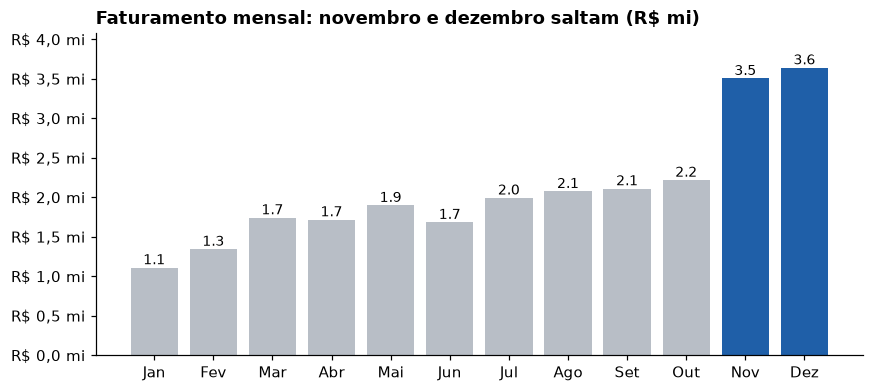

Nov + Dez: R$ 7,14 mi = 28.6% do ano em 2 meses (parcela esperada de 2 meses: 16.7%)
Média mensal Jan-Out: R$ 1,79 mi | Média Nov-Dez: R$ 3,57 mi
Vendas por mês: [243, 249, 362, 335, 393, 358, 383, 435, 411, 432, 654, 745]


In [5]:
mes = df.groupby('mes')['faturamento'].sum()
nomes = ['Jan','Fev','Mar','Abr','Mai','Jun','Jul','Ago','Set','Out','Nov','Dez']
fig, ax = plt.subplots(figsize=(9, 3.8))
b = ax.bar(nomes, mes.values, color=[COR if m >= 11 else CINZA for m in mes.index])
for r, val in zip(b, mes.values):
    ax.text(r.get_x()+r.get_width()/2, val, f'{val/1e6:.1f}', ha='center', va='bottom', fontsize=9)
ax.yaxis.set_major_formatter(mi); ax.set_ylim(0, mes.max()*1.12)
ax.set_title('Faturamento mensal: novembro e dezembro saltam (R$ mi)')
plt.show()
nd = mes.loc[[11, 12]].sum()
print(f'Nov + Dez: {fmt_mi(nd)} = {nd/TOTAL:.1%} do ano em 2 meses (parcela esperada de 2 meses: {2/12:.1%})')
print(f'Média mensal Jan-Out: {fmt_mi(mes.loc[:10].mean())} | Média Nov-Dez: {fmt_mi(mes.loc[[11,12]].mean())}')
print('Vendas por mês:', df.groupby('mes').size().tolist())

O ano começa fraco (jan: R$ 1,1 mi), cresce de forma gradual até outubro (R$ 2,2 mi) e **salta em novembro e dezembro** (R$ 3,5 mi e R$ 3,6 mi). Esses dois meses concentram **28,6% do faturamento anual**.
O salto vem de mais vendas (654 e 745 vendas, contra 240 a 435 nos meses anteriores), não de vendas maiores. Os dados não dizem a causa; sazonalidade de fim de ano e promoções são hipóteses a confirmar com a área comercial.

,Jan,Fev,Mar,Abr,Mai,Jun,Jul,Ago,Set,Out,Nov,Dez
regiao,,,,,,,,,,,,
Sudeste,490,605,591,620,674,631,766,713,778,988,"1,537","1,433"
Sul,153,191,395,349,376,371,243,477,412,345,551,516
Nordeste,232,208,309,323,269,289,384,298,316,367,562,584
Centro-Oeste,124,195,189,229,252,188,203,256,289,225,420,517
Norte,76,113,201,182,241,169,339,259,282,224,273,496
Não informada,32,30,56,12,85,34,56,71,31,67,161,92


,Jan,Fev,Mar,Abr,Mai,Jun,Jul,Ago,Set,Out,Nov,Dez
regiao,,,,,,,,,,,,
Sudeste,44%,45%,34%,36%,36%,37%,38%,34%,37%,45%,44%,39%
Sul,14%,14%,23%,20%,20%,22%,12%,23%,20%,16%,16%,14%
Nordeste,21%,15%,18%,19%,14%,17%,19%,14%,15%,17%,16%,16%
Centro-Oeste,11%,15%,11%,13%,13%,11%,10%,12%,14%,10%,12%,14%
Norte,7%,8%,12%,11%,13%,10%,17%,12%,13%,10%,8%,14%


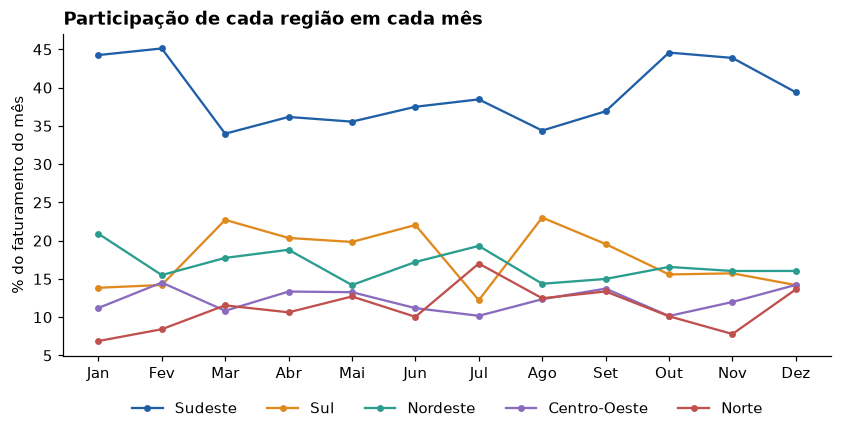

In [6]:
mr = df.pivot_table(index='regiao', columns='mes', values='faturamento', aggfunc='sum').loc[ordem]
mr.columns = nomes
display((mr/1e3).style.format('{:,.0f}').background_gradient(cmap='Blues', axis=1).set_caption('Faturamento por região e mês (R$ mil). Cor: força do mês dentro de cada região'))
cr = (mr.div(mr.sum())*100).loc[['Sudeste','Sul','Nordeste','Centro-Oeste','Norte']]
display(cr.style.format('{:.0f}%').set_caption('Participação de cada região no faturamento do mês (as regiões somam 100% com "Não informada")'))
fig, ax = plt.subplots(figsize=(9, 3.8))
for r, c in zip(cr.index, ['#1f5fa8', '#e08a1e', '#2a9d8f', '#8a6bbe', '#c0504d']):
    ax.plot(cr.columns, cr.loc[r], marker='o', ms=3.5, label=r, color=c)
ax.set_ylabel('% do faturamento do mês'); ax.legend(ncol=5, frameon=False, loc='upper center', bbox_to_anchor=(0.5, -0.1))
ax.set_title('Participação de cada região em cada mês')
plt.show()

A participação das regiões **muda ao longo do ano**. O Sudeste pesa 44-45% em janeiro, fevereiro, outubro e novembro, e fica entre 34% e 38% de março a setembro. O Sul faz o inverso: 14-16% nos meses fortes do Sudeste e 19-23% de março a setembro, exceto julho (12%). Com poucas centenas de vendas por região em cada mês, parte da oscilação é ruído, mas o padrão dura meses seguidos.

## 4. Por canal de venda

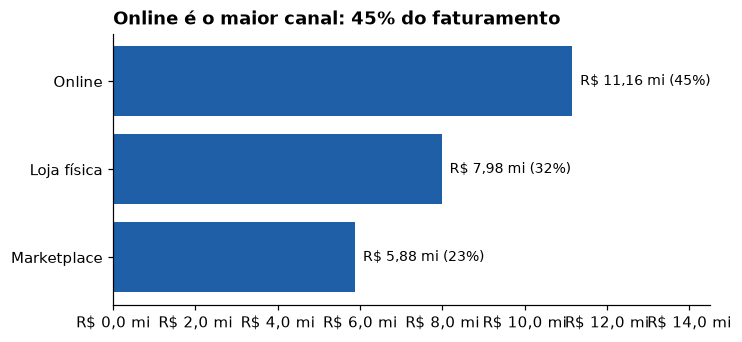

canal_venda,Loja física,Marketplace,Online
regiao,,,
Sudeste,3.28,2.16,4.39
Sul,1.47,0.91,1.99
Nordeste,1.18,1.15,1.81
Centro-Oeste,0.98,0.73,1.37
Norte,0.86,0.76,1.24
Não informada,0.21,0.17,0.35


canal_venda,Loja física,Marketplace,Online
regiao,,,
Sudeste,33%,22%,45%
Sul,34%,21%,46%
Nordeste,28%,28%,44%
Centro-Oeste,32%,24%,45%
Norte,30%,27%,43%
Não informada,29%,23%,48%


In [7]:
can = df.groupby('canal_venda')['faturamento'].sum().sort_values(ascending=False)
fig, ax = plt.subplots(figsize=(7, 3.2))
b = ax.barh(can.index[::-1], can.values[::-1], color=COR)
for r, val in zip(b, can.values[::-1]):
    ax.text(val, r.get_y()+r.get_height()/2, f'  {fmt_mi(val)} ({val/TOTAL:.0%})', va='center', fontsize=9)
ax.xaxis.set_major_formatter(mi); ax.set_xlim(0, can.max()*1.3)
ax.set_title('Online é o maior canal: 45% do faturamento')
plt.show()

mix = df.pivot_table(index='regiao', columns='canal_venda', values='faturamento', aggfunc='sum').loc[ordem]
mixp = mix.div(mix.sum(axis=1), axis=0)*100
display((mix/1e6).style.format('{:.2f}').set_caption('Faturamento por região e canal (R$ mi)'))
display(mixp.style.format('{:.0f}%').set_caption('Mix de canais dentro de cada região (% da região)'))

O **Online** lidera (R$ 11,16 mi, 45%), seguido por Loja física (R$ 7,98 mi, 32%) e Marketplace (R$ 5,88 mi, 23%). O Online é o maior canal **em todas as regiões**, com peso parecido (43% a 46%, ignorando "Não informada").
A diferença está no Marketplace: pesa mais no Nordeste (28%) e no Norte (27%) e menos no Sul (21%) e no Sudeste (22%).

## 5. E a rentabilidade?
O custo unitário permite ver se alguma região ou canal vende muito, mas com pouca margem. Margem = lucro ÷ faturamento, com lucro = quantidade × (preço − custo).

In [8]:
def margem(col):
    g = df.groupby(col)[['faturamento', 'lucro']].sum()
    return (g.lucro/g.faturamento*100).sort_values(ascending=False).rename('Margem')
print(f'Margem geral: {df.lucro.sum()/TOTAL:.1%}')
display(margem('regiao').to_frame().style.format('{:.1f}%'))
display(margem('canal_venda').to_frame().style.format('{:.1f}%'))

Margem geral: 36.3%


,Margem
regiao,
Centro-Oeste,36.5%
Norte,36.4%
Nordeste,36.4%
Não informada,36.3%
Sul,36.3%
Sudeste,36.3%


,Margem
canal_venda,
Loja física,36.4%
Online,36.4%
Marketplace,36.2%


A margem é **praticamente igual em todas as regiões e canais (36,2% a 36,5%)**. Nenhuma região ou canal vende com lucro percentual muito diferente: **onde há mais faturamento, há proporcionalmente mais lucro**, e a decisão pode se guiar pelo faturamento.

## 6. Conclusão para a diretoria

**Onde está o faturamento de 2025 (R$ 25,02 mi):**
- **Região:** Sudeste 39% (R$ 9,83 mi); Sul 17,5% e Nordeste 16,6% (R$ 4,38 mi e R$ 4,14 mi); Centro-Oeste 12,3% e Norte 11,4%.
- **Mês:** crescimento gradual de janeiro a outubro e salto em **novembro e dezembro, 28,6% do ano**.
- **Canal:** Online 45%, Loja física 32%, Marketplace 23%. O Online lidera em todas as regiões.
- **Margem:** igual em todo lugar (~36%), então mais faturamento significa mais lucro.

**Sugestões para 2026:**
1. **Proteger o Sudeste e o Online.** São as maiores fontes de receita; uma queda ali pesa mais que qualquer ganho nas outras regiões.
2. **Preparar novembro e dezembro com antecedência** (estoque, equipe, campanhas). Esse período vale mais de um quarto do ano.
3. **Ampliar Sul e Nordeste, a segunda faixa de receita.** Têm ticket e margem iguais aos do Sudeste. O que falta é volume de vendas, então a alavanca é **mais clientes e pedidos**, não preço.
4. **Marketplace** é mais fraco no Sul e no Sudeste (21-22%) e mais forte no Norte e Nordeste (27-28%); vale testar se há espaço para crescer onde ele é fraco ou reforçá-lo onde já funciona.

**Limites desta análise:**
- Um único ano de dados: não dá para dizer se o salto de nov/dez é padrão recorrente ou efeito de 2025.
- Não há dados de população, clientes ou custo comercial por região, então não sabemos se Norte e Centro-Oeste faturam pouco por falta de mercado ou de presença. Isso precisa ser verificado antes de decidir investir ali.
- 2,9% do faturamento está sem região informada.